Code by Hans Ekkehard Plesser

# Principal Component Analysis (PCA)

In [25]:
#==============================================================================
# Import modules
#==============================================================================

import numpy as np

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings("ignore")

plt.rcParams['figure.figsize'] = (12, 6)

In [26]:
#==============================================================================
# Load data and select features
#==============================================================================

iris = datasets.load_iris()
X = iris.data[:, :]
y = iris.target

In [27]:
#==============================================================================
# Split into training and test data
#==============================================================================

# Print lables of all all classes in data set
print('Class labels:', np.unique(y))


# Split data into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y)


Class labels: [0 1 2]


In [28]:
#==============================================================================
# Scale features using StandardScaler class in ScikitLearn 
#==============================================================================

# Initialise standard scaler and compute mean and STD from training data
sc = StandardScaler()
sc.fit(X_train)


# Transform (standardise) both X_train and X_test with mean and STD from
# training data
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

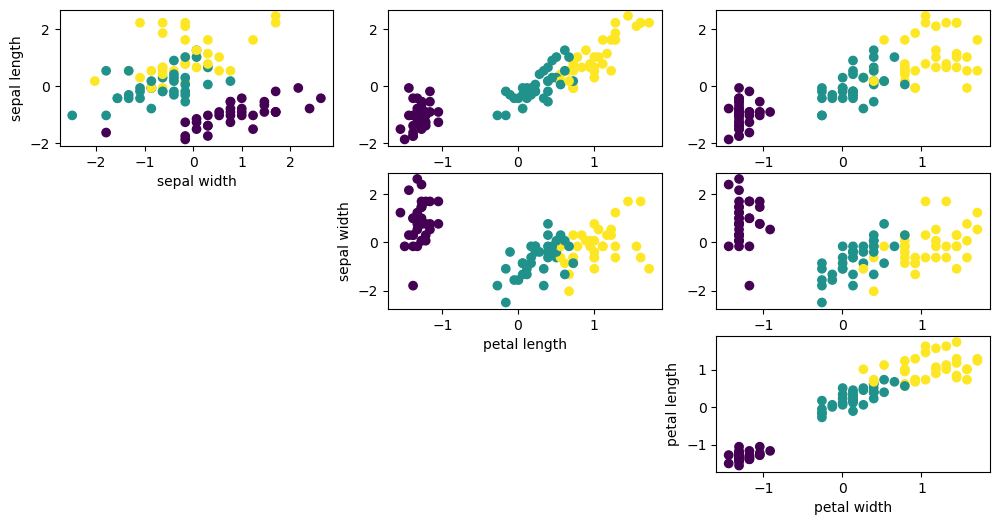

In [29]:
#==============================================================================
# Plot all possible pairs of the four features
#==============================================================================

features = ['sepal length', 'sepal width', 'petal length', 'petal width']
gs = gridspec.GridSpec(3, 3)
plt.figure()
for ny in range(3):
    for nx in range(ny+1, 4):
        plt.subplot(gs[ny, nx-1])
        plt.scatter(X_train_std[:, nx], X_train_std[:, ny], c=y_train);
        if ny == nx-1:
            plt.xlabel(features[nx])
            plt.ylabel(features[ny]);

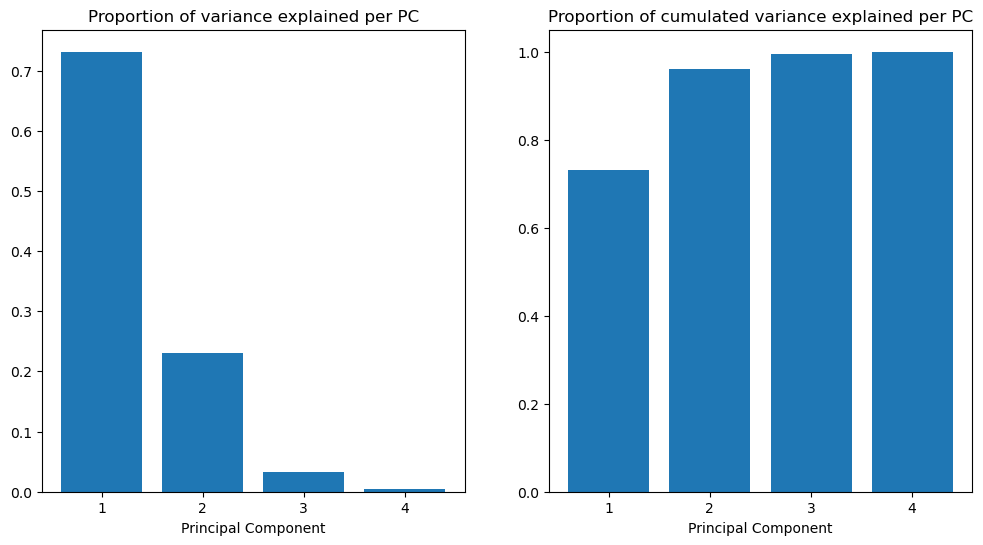

In [30]:
#==============================================================================
# Perform a PCA on the training data, keeping all components
#==============================================================================
            
from sklearn.decomposition import PCA

# Construct pca object that will do the work for us
pca = PCA()

# Fit a model to the training data; unsupervised---no labels needed
X_train_PCA = pca.fit_transform(X_train_std)

# Plot explained variance 
plt.figure()
plt.subplot(1, 2, 1)
plt.bar(range(1, 5), pca.explained_variance_ratio_)
plt.title('Proportion of variance explained per PC')
plt.xlabel('Principal Component')
plt.xticks(range(1, 5));

# Plot cumulated variance explained
plt.subplot(1, 2, 2)
plt.bar(range(1, 5), pca.explained_variance_ratio_.cumsum())
plt.title('Proportion of cumulated variance explained per PC')
plt.xlabel('Principal Component')
plt.xticks(range(1, 5));

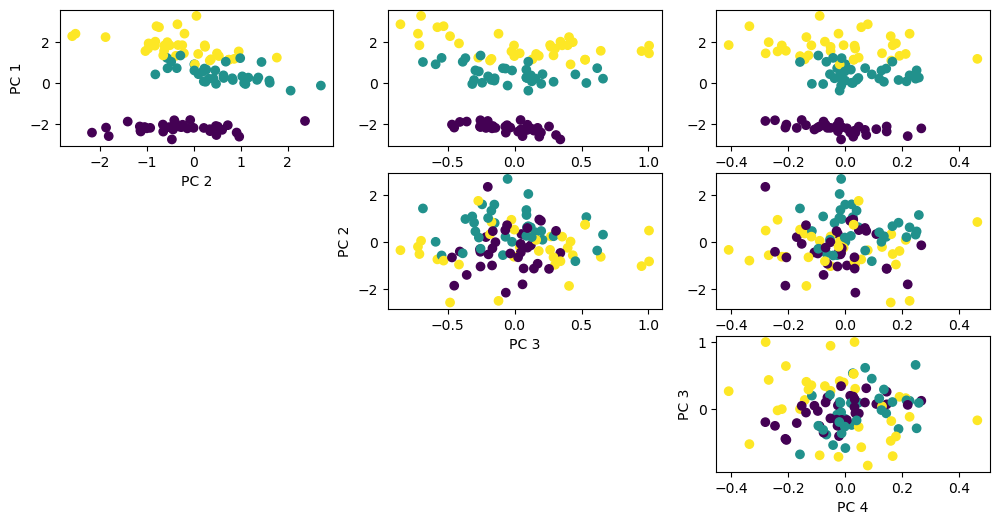

In [31]:
#==============================================================================
# Plot the principal components for the training data
#==============================================================================

plt.figure()
for ny in range(3):
    for nx in range(ny+1, 4):
        plt.subplot(gs[ny, nx-1])
        plt.scatter(X_train_PCA[:, nx], X_train_PCA[:, ny], c=y_train);
        if ny == nx-1:
            plt.xlabel('PC {}'.format(nx+1))
            plt.ylabel('PC {}'.format(ny+1));

In [32]:
#==============================================================================
# PCA as a pre-processing method for dimensional reduction
#
# 1. Perform a PCA, keeping only two components
# 2. Perform a logistic regression on the PCA-transformed data  
# Note: Also test data must be transformed to the new coordinates!
#==============================================================================

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

lr = LogisticRegression()
lr = lr.fit(X_train_pca, y_train)

In [33]:
#==============================================================================
# Make predictions for the test set
#==============================================================================

# Predict classes for the samples in the test set and print the number of misclassfications
y_pred = lr.predict(X_test_pca)
print('Misclassified samples: {0}'.format((y_test != y_pred).sum()))


Misclassified samples: 7


In [34]:
#==============================================================================
# Compute performance metrics in a couple of ways
#==============================================================================

# Print accuracy computed from predictions on the test set
print('Accuracy: {0:.2f}'.format(accuracy_score(y_test, y_pred)))


# Print accuracy computed from predictions on the test set
print('Accuracy: {0:.2f}'.format(lr.score(X_test_pca, y_test)))


Accuracy: 0.84
Accuracy: 0.84


In [35]:
#==============================================================================
# Define a function for plotting with decision regions
#==============================================================================

def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):

    # Setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # Plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], 
                    y=X[y == cl, 1],
                    alpha=0.8, 
                    c=colors[idx],
                    marker=markers[idx], 
                    label=cl, 
                    edgecolor='black')
    
    # Highlight test samples
    if test_idx:
        # Plot all samples
        X_test, y_test = X[test_idx, :], y[test_idx]

        plt.scatter(X_test[:, 0],
                    X_test[:, 1],
                    c='',
                    edgecolor='black',
                    alpha=1.0,
                    linewidth=1,
                    marker='o',
                    s=100, 
                    label='test set')


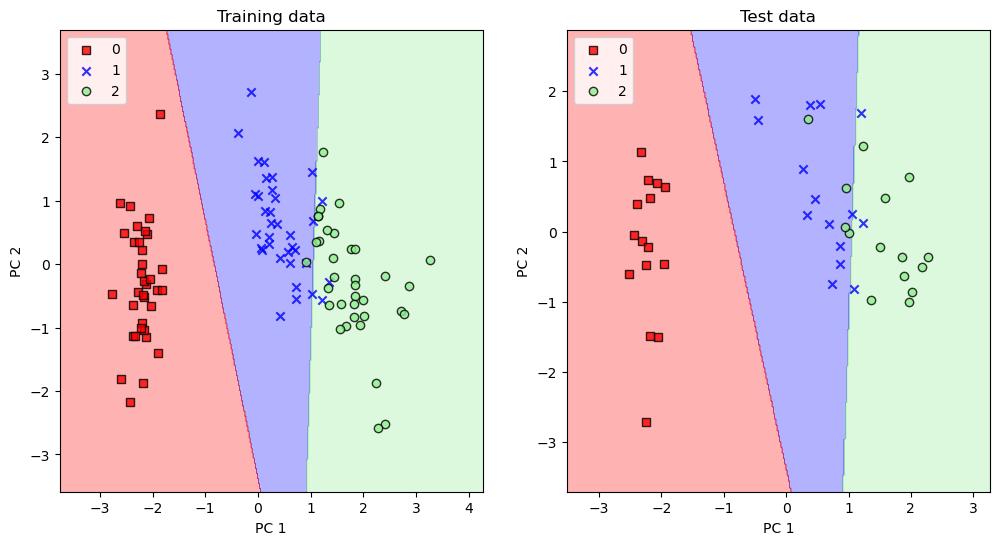

In [36]:
#==============================================================================
# Plot the results with the plot function for decision regions
#==============================================================================

plt.figure()
plt.subplot(1, 2, 1)
plot_decision_regions(X=X_train_pca, y=y_train, classifier=lr)
plt.title('Training data')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(loc='upper left')

plt.subplot(1, 2, 2)
plot_decision_regions(X=X_test_pca, y=y_test, classifier=lr)
plt.title('Test data')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(loc='upper left');